# Phase 4 — Vérification de la tokenisation Qwen

**Projet : Continuous LoRA Fine-Tuning Pipeline for Customer Support**

| | |
|---|---|
| Modèle | `Qwen/Qwen2.5-1.5B-Instruct` (seul le **tokenizer** est chargé) |
| Dataset | `bitext/Bitext-customer-support-llm-chatbot-training-dataset` (préparé localement, suivi par DVC) |
| Dépôt | https://github.com/siham200/continuous-lora-pipeline |
| Runtime | **CPU suffisant** (la tokenisation n'a pas besoin de GPU) |

## Mode d'emploi
1. Exécuter les cellules **dans l'ordre** (`Exécution > Tout exécuter`).
2. À l'étape 2, téléverser l'archive ZIP contenant : `train_batch1.jsonl` (400), `train_batch2.jsonl` (200), `validation.jsonl` (100), `test.jsonl` (100).
3. À la fin, les trois rapports sont téléchargés : `tokenization_report.json`, `token_lengths.csv`, `token_length_histogram.png`.

## Garanties
- Aucun `git push`, aucun `dvc push`, aucune authentification Google Drive.
- Les fichiers originaux de l'utilisateur ne sont jamais modifiés (le ZIP est seulement lu).
- Aucun texte de conversation n'est écrit dans les rapports.
- Aucune troncature : cette phase **mesure** uniquement.
- Après une réinitialisation de session, il suffit de tout relancer et de téléverser à nouveau le ZIP.

## Étape 0 — Initialisation
Paramètres globaux, vérification de Python / PyTorch / CUDA et création des dossiers de travail.

In [1]:
# ============================================================
# Étape 0 — Initialisation de l'environnement
# ============================================================
import os
import sys
import re
import csv
import io
import json
import time
import shutil
import hashlib
import zipfile
import subprocess
import statistics
from collections import Counter
from datetime import datetime, timezone
from pathlib import Path, PurePosixPath

import torch

# ---------- Paramètres du projet ----------
REPO_URL = "https://github.com/siham200/continuous-lora-pipeline.git"
REPO_DIR = Path("/content/continuous-lora-pipeline")
MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"

EXPECTED_FILES = {
    "train_batch1.jsonl": 400,
    "train_batch2.jsonl": 200,
    "validation.jsonl": 100,
    "test.jsonl": 100,
}
EXPECTED_TOTAL = 800
THRESHOLDS = [512, 1024, 2048, 4096]

# ---------- Dossiers de travail ----------
WORK_DIR = Path("/content/phase4_work")        # ZIP téléversé (copie de travail)
OUTPUT_DIR = Path("/content/phase4_outputs")   # rapports générés
for directory in (WORK_DIR, OUTPUT_DIR):
    directory.mkdir(parents=True, exist_ok=True)

# ---------- Suivi de l'état de la phase ----------
STATUS = {
    "repo_cloned": False,
    "dataset_valid": False,
    "tokenizer_loaded": False,
    "tokenized": False,
    "reports_written": False,
}

# ---------- Vérification de l'environnement ----------
print("Python           :", sys.version.split()[0])
print("PyTorch          :", torch.__version__)
print("CUDA disponible  :", torch.cuda.is_available())
if torch.cuda.is_available():
    props = torch.cuda.get_device_properties(0)
    print("GPU              :", torch.cuda.get_device_name(0))
    print("Mémoire GPU      :", round(props.total_memory / 1024**3, 2), "GB")
else:
    print("GPU              : aucun (la tokenisation s'exécute très bien sur CPU)")

print("\nDossier de travail :", WORK_DIR)
print("Dossier de sortie  :", OUTPUT_DIR)

Python           : 3.13.16
PyTorch          : 2.14.1+cu130
CUDA disponible  : True
GPU              : Tesla T4
Mémoire GPU      : 14.56 GB

Dossier de travail : /content/phase4_work
Dossier de sortie  : /content/phase4_outputs


## Étape 1 — Connexion GitHub
Clonage du dépôt **public** (sans token, sans prompt d'authentification) et vérification de la branche et de l'URL.
Le notebook ne pousse **jamais** de modification vers GitHub.

In [2]:
# ============================================================
# Étape 1 — Clonage du dépôt GitHub (lecture seule)
# ============================================================
GIT_ENV = {**os.environ, "GIT_TERMINAL_PROMPT": "0"}   # jamais de demande d'identifiants

def git(args, cwd=None, timeout=180):
    return subprocess.run(["git"] + args, cwd=cwd, env=GIT_ENV,
                          capture_output=True, text=True, timeout=timeout)

def normalize_url(url):
    return re.sub(r"\.git$", "", url.strip().rstrip("/")).lower()

def print_tree(root, max_depth=2, _prefix="", _depth=0):
    # Affiche l'arborescence (sans .git ni caches).
    ignored = {".git", "__pycache__", ".ipynb_checkpoints"}
    entries = sorted(
        [p for p in Path(root).iterdir() if p.name not in ignored],
        key=lambda p: (p.is_file(), p.name.lower()),
    )
    for i, p in enumerate(entries):
        last = i == len(entries) - 1
        print(f"{_prefix}{'└── ' if last else '├── '}{p.name}{'/' if p.is_dir() else ''}")
        if p.is_dir() and _depth + 1 < max_depth:
            print_tree(p, max_depth, _prefix + ("    " if last else "│   "), _depth + 1)

try:
    if (REPO_DIR / ".git").exists():
        print("Dépôt déjà présent : mise à jour en fast-forward (lecture seule).")
        result = git(["pull", "--ff-only"], cwd=REPO_DIR)
        print((result.stdout or result.stderr).strip())
        STATUS["repo_cloned"] = True
    elif REPO_DIR.exists() and any(REPO_DIR.iterdir()):
        print("⚠️ Le dossier existe déjà sans dépôt Git : clonage ignoré pour ne rien écraser.")
    else:
        print("Clonage de", REPO_URL)
        result = git(["clone", "--depth", "1", REPO_URL, str(REPO_DIR)])
        if result.returncode != 0:
            raise RuntimeError(result.stderr.strip() or "git clone a échoué")
        STATUS["repo_cloned"] = True
        print("Clonage terminé.")
except Exception as exc:
    print(f"⚠️ Impossible de cloner le dépôt : {exc}")
    print("   Le notebook continue : seul le dossier data/processed est nécessaire.")

REPO_DIR.mkdir(parents=True, exist_ok=True)

if (REPO_DIR / ".git").exists():
    branch = git(["rev-parse", "--abbrev-ref", "HEAD"], cwd=REPO_DIR).stdout.strip()
    remote = git(["remote", "get-url", "origin"], cwd=REPO_DIR).stdout.strip()
    last_commit = git(["log", "-1", "--oneline"], cwd=REPO_DIR).stdout.strip()
    print("\nBranche         :", branch)
    print("Remote origin   :", remote)
    print("Dernier commit  :", last_commit)
    if normalize_url(remote) != normalize_url(REPO_URL):
        print("⚠️ L'URL du remote diffère de l'URL attendue !")
    else:
        print("URL du remote conforme.")

print("\nStructure du projet :")
print(REPO_DIR.name + "/")
print_tree(REPO_DIR, max_depth=2)

Clonage de https://github.com/siham200/continuous-lora-pipeline.git
Clonage terminé.

Branche         : main
Remote origin   : https://github.com/siham200/continuous-lora-pipeline.git
Dernier commit  : 6aff5d3 Update dataset version after JSONL repair
URL du remote conforme.

Structure du projet :
continuous-lora-pipeline/
├── .dvc/
│   ├── .gitignore
│   └── config
├── .github/
│   └── workflows/
├── configs/
│   └── qlora_config.yaml
├── data/
│   ├── raw/
│   ├── .gitignore
│   └── processed.dvc
├── models/
│   └── .gitkeep
├── notebooks/
│   └── .gitkeep
├── reports/
│   ├── cycle_1/
│   └── cycle_2/
├── src/
│   ├── data/
│   ├── evaluation/
│   ├── registry/
│   └── training/
├── tests/
│   ├── .gitkeep
│   └── __init__.py
├── .dvcignore
├── .gitignore
├── dvc.yaml
├── README.md
└── requirements.txt


## Étape 2 — Importation des données
Téléversez votre archive ZIP. Elle est :
1. vérifiée (extension `.zip`, intégrité) ;
2. analysée **sans extraction globale** (chemins dangereux et archives trop volumineuses rejetés) ;
3. recherchée récursivement pour retrouver les 4 fichiers JSONL, même dans un sous-dossier ;
4. copiée dans `data/processed`. Si un fichier différent existe déjà, un **avertissement** est affiché et une sauvegarde est créée avant remplacement.

In [3]:
# ============================================================
# Étape 2a — Téléversement de l'archive ZIP
# ============================================================
try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

os.chdir("/content" if Path("/content").exists() else ".")   # files.upload() écrit dans le dossier courant

if IN_COLAB:
    print("Sélectionnez l'archive ZIP contenant les 4 fichiers JSONL…")
    uploaded = files.upload()
    if not uploaded:
        raise RuntimeError("Aucun fichier téléversé. Relancez la cellule.")

    zip_names = [name for name in uploaded if name.lower().endswith(".zip")]
    if not zip_names:
        raise ValueError(f"Aucune archive .zip reçue (fichiers reçus : {list(uploaded)}).")
    if len(zip_names) > 1:
        print(f"⚠️ Plusieurs ZIP reçus {zip_names} : le dernier est utilisé.")
    uploaded_name = zip_names[-1]

    ZIP_PATH = WORK_DIR / "dataset_upload.zip"
    ZIP_PATH.write_bytes(uploaded[uploaded_name])
    # Colab a aussi écrit des copies dans le dossier courant : on les supprime.
    for name in uploaded:
        try:
            Path(name).unlink()
        except OSError:
            pass
else:
    ZIP_PATH = Path(input("Chemin local de l'archive ZIP : ").strip())
    if ZIP_PATH.suffix.lower() != ".zip":
        raise ValueError("Le fichier doit avoir l'extension .zip")

if not zipfile.is_zipfile(ZIP_PATH):
    raise ValueError("Le fichier n'est pas une archive ZIP valide.")
with zipfile.ZipFile(ZIP_PATH) as archive:
    bad_member = archive.testzip()
    if bad_member:
        raise ValueError(f"Archive corrompue (membre défectueux : {bad_member}).")

print("Archive importée :", uploaded_name if IN_COLAB else ZIP_PATH.name)
print("Taille           :", round(ZIP_PATH.stat().st_size / 1024, 1), "Ko")

Sélectionnez l'archive ZIP contenant les 4 fichiers JSONL…


Saving customer_support_dataset (1).zip to customer_support_dataset (1).zip
Archive importée : customer_support_dataset (1).zip
Taille           : 142.5 Ko


In [4]:
# ============================================================
# Étape 2b — Extraction sécurisée vers data/processed
# ============================================================
DATA_DIR = REPO_DIR / "data" / "processed"
DATA_DIR.mkdir(parents=True, exist_ok=True)

MAX_MEMBER_BYTES = 200 * 1024 * 1024    # 200 Mo par fichier requis
MAX_TOTAL_BYTES = 500 * 1024 * 1024     # 500 Mo décompressés au total (anti zip-bomb)

def is_unsafe_member(name):
    posix = PurePosixPath(name.replace("\\", "/"))
    return posix.is_absolute() or ".." in posix.parts

def sha256_bytes(data):
    return hashlib.sha256(data).hexdigest()

with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    infos = [i for i in archive.infolist() if not i.is_dir()]

    total_uncompressed = sum(i.file_size for i in infos)
    if total_uncompressed > MAX_TOTAL_BYTES:
        raise ValueError(f"Archive trop volumineuse une fois décompressée ({total_uncompressed/1024**2:.0f} Mo).")

    unsafe = [i.filename for i in infos if is_unsafe_member(i.filename)]
    if unsafe:
        print(f"⚠️ {len(unsafe)} entrée(s) à chemin dangereux ignorée(s) : {unsafe[:5]}")

    # Recherche des fichiers requis par leur nom, quel que soit le sous-dossier
    candidates = {name: [] for name in EXPECTED_FILES}
    for info in infos:
        if is_unsafe_member(info.filename) or "__MACOSX" in info.filename.split("/"):
            continue
        base = PurePosixPath(info.filename.replace("\\", "/")).name
        if base in candidates:
            candidates[base].append(info)

    missing = [name for name, found in candidates.items() if not found]
    if missing:
        raise FileNotFoundError(f"Fichiers manquants dans l'archive : {missing}")
    ambiguous = {n: [i.filename for i in f] for n, f in candidates.items() if len(f) > 1}
    if ambiguous:
        raise ValueError(f"Plusieurs fichiers portent le même nom dans l'archive : {ambiguous}")

    backup_dir = DATA_DIR / "_backup" / datetime.now().strftime("%Y%m%d_%H%M%S")
    print(f"{'Fichier':<22}{'Chemin dans le ZIP':<40}{'Action'}")
    print("-" * 80)

    for filename, (info,) in candidates.items():
        if info.file_size > MAX_MEMBER_BYTES:
            raise ValueError(f"{filename} dépasse la taille maximale autorisée.")
        data = archive.read(info)            # lecture en mémoire : aucune écriture au chemin du ZIP
        destination = DATA_DIR / filename

        if destination.exists():
            if sha256_bytes(destination.read_bytes()) == sha256_bytes(data):
                action = "identique → conservé"
            else:
                backup_dir.mkdir(parents=True, exist_ok=True)
                shutil.copy2(destination, backup_dir / filename)
                destination.write_bytes(data)
                action = "⚠️ DIFFÉRENT → remplacé (sauvegarde dans _backup)"
        else:
            destination.write_bytes(data)
            action = "copié"
        print(f"{filename:<22}{info.filename:<40}{action}")

print("\nContenu de", DATA_DIR)
for p in sorted(DATA_DIR.glob("*.jsonl")):
    print(f"  {p.name:<22}{p.stat().st_size / 1024:>10.1f} Ko")

Fichier               Chemin dans le ZIP                      Action
--------------------------------------------------------------------------------
train_batch1.jsonl    train_batch1.jsonl                      copié
train_batch2.jsonl    train_batch2.jsonl                      copié
validation.jsonl      validation.jsonl                        copié
test.jsonl            test.jsonl                              copié

Contenu de /content/continuous-lora-pipeline/data/processed
  test.jsonl                  95.8 Ko
  train_batch1.jsonl         392.0 Ko
  train_batch2.jsonl         191.9 Ko
  validation.jsonl           104.8 Ko


In [7]:

import json
from pathlib import Path

EXPECTED_FILES = {
    "train_batch1.jsonl": 400,
    "train_batch2.jsonl": 200,
    "validation.jsonl": 100,
    "test.jsonl": 100
}

VALID_ROLES = ["system", "user", "assistant"]

print("Début de la vérification et réparation...\n")

for filename, expected_count in EXPECTED_FILES.items():

    path = DATA_DIR / filename

    if not path.exists():
        raise FileNotFoundError(f"Fichier introuvable : {filename}")

    # Lire le contenu original
    content = path.read_text(encoding="utf-8-sig")

    decoder = json.JSONDecoder()
    records = []
    pos = 0

    # Lire les objets JSON successifs, même si les séparateurs
    # sont des caractères littéraux \ et n.
    while pos < len(content):

        while pos < len(content) and content[pos].isspace():
            pos += 1

        # Ignorer les séparateurs littéraux \n entre les objets
        while content.startswith("\\n", pos):
            pos += 2

            while pos < len(content) and content[pos].isspace():
                pos += 1

        if pos >= len(content):
            break

        obj, end = decoder.raw_decode(content, pos)

        if not isinstance(obj, dict):
            raise ValueError(f"{filename}: objet JSON invalide")

        if not isinstance(obj.get("messages"), list):
            raise ValueError(f"{filename}: champ messages invalide")

        roles = [
            message.get("role")
            for message in obj["messages"]
        ]

        if roles != VALID_ROLES:
            raise ValueError(
                f"{filename}: rôles incorrects : {roles}"
            )

        records.append(obj)
        pos = end

    # Vérifier le nombre attendu avant toute modification
    if len(records) != expected_count:
        raise ValueError(
            f"{filename}: {len(records)} conversations détectées, "
            f"{expected_count} attendues. Fichier non modifié."
        )

    # Créer une sauvegarde
    backup = path.with_name(path.name + ".before_repair")

    if not backup.exists():
        backup.write_bytes(path.read_bytes())

    # Réécrire au vrai format JSONL
    temp = path.with_suffix(path.suffix + ".tmp")

    with temp.open("w", encoding="utf-8", newline="\n") as f:
        for record in records:
            f.write(json.dumps(record, ensure_ascii=False) + "\n")

    temp.replace(path)

    print(f"OK : {filename} — {len(records)} conversations")

print("\nRéparation terminée.")


Début de la vérification et réparation...

OK : train_batch1.jsonl — 400 conversations
OK : train_batch2.jsonl — 200 conversations
OK : validation.jsonl — 100 conversations
OK : test.jsonl — 100 conversations

Réparation terminée.


## Étape 3 — Validation du dataset
Contrôles effectués sur chaque ligne : JSON valide, clé `messages`, rôles exactement `system → user → assistant`, contenus de type `str` non vides, conversations vides, doublons exacts (dans un fichier et entre fichiers).

- **Erreurs critiques** (JSON invalide, structure, rôles, contenus, nombre de lignes) → le notebook s'arrête.
- **Avertissements** (doublons, lignes vides) → signalés sans bloquer.

In [8]:
# ============================================================
# Étape 3 — Validation du dataset
# ============================================================
VALID_ROLES = ["system", "user", "assistant"]

critical_errors = []      # bloquantes
warnings_list = []        # non bloquantes
all_records = {}          # fichier -> liste de conversations valides
validation_report = {}    # fichier -> compteurs
seen_global = {}          # empreinte -> (fichier, n° de ligne)
duplicate_cross = []

def fingerprint(messages):
    key = json.dumps(messages, ensure_ascii=False, sort_keys=True)
    return hashlib.sha256(key.encode("utf-8")).hexdigest()

for filename, expected in EXPECTED_FILES.items():
    path = DATA_DIR / filename
    info = {
        "expected": expected, "lines_total": 0, "blank_lines": 0, "non_empty_lines": 0,
        "valid_records": 0, "invalid_json": 0, "invalid_structure": 0, "empty_conversations": 0,
        "invalid_roles": 0, "invalid_contents": 0, "duplicates_within_file": 0,
    }
    records = []
    seen_local = {}

    if not path.exists():
        critical_errors.append(f"{filename} — fichier introuvable dans {DATA_DIR}")
        validation_report[filename] = info
        continue

    with path.open("r", encoding="utf-8-sig") as handle:
        for line_no, raw in enumerate(handle, 1):
            info["lines_total"] += 1
            line = raw.strip()
            if not line:
                info["blank_lines"] += 1
                continue
            info["non_empty_lines"] += 1

            # 1) JSON valide
            try:
                obj = json.loads(line)
            except json.JSONDecodeError as exc:
                info["invalid_json"] += 1
                critical_errors.append(f"{filename}:{line_no} — JSON invalide ({exc.msg})")
                continue

            # 2) Présence de "messages"
            if not isinstance(obj, dict) or "messages" not in obj:
                info["invalid_structure"] += 1
                critical_errors.append(f"{filename}:{line_no} — clé 'messages' absente")
                continue
            messages = obj["messages"]
            if not isinstance(messages, list):
                info["invalid_structure"] += 1
                critical_errors.append(f"{filename}:{line_no} — 'messages' n'est pas une liste")
                continue

            # 3) Conversation vide
            if len(messages) == 0:
                info["empty_conversations"] += 1
                critical_errors.append(f"{filename}:{line_no} — conversation vide")
                continue

            # 4) Rôles
            roles = [m.get("role") if isinstance(m, dict) else None for m in messages]
            if roles != VALID_ROLES:
                info["invalid_roles"] += 1
                critical_errors.append(f"{filename}:{line_no} — rôles inattendus : {roles}")
                continue

            # 5) Contenus : chaînes non vides
            bad = [m["role"] for m in messages
                   if not isinstance(m.get("content"), str) or not m["content"].strip()]
            if bad:
                info["invalid_contents"] += 1
                critical_errors.append(f"{filename}:{line_no} — contenu vide ou non textuel ({bad})")
                continue

            # 6) Doublons exacts
            fp = fingerprint(messages)
            if fp in seen_local:
                info["duplicates_within_file"] += 1
                warnings_list.append(f"{filename}:{line_no} — doublon exact de la ligne {seen_local[fp]}")
            else:
                seen_local[fp] = line_no
                if fp in seen_global:
                    other_file, other_line = seen_global[fp]
                    duplicate_cross.append((filename, line_no, other_file, other_line))
                    warnings_list.append(
                        f"{filename}:{line_no} — doublon exact de {other_file}:{other_line} (fichiers différents)")
                else:
                    seen_global[fp] = (filename, line_no)

            records.append(obj)

    info["valid_records"] = len(records)
    if info["non_empty_lines"] != expected:
        critical_errors.append(
            f"{filename} — {info['non_empty_lines']} lignes non vides au lieu de {expected} attendues")
    if info["blank_lines"]:
        warnings_list.append(f"{filename} — {info['blank_lines']} ligne(s) vide(s) ignorée(s)")

    all_records[filename] = records
    validation_report[filename] = info

total_valid = sum(len(r) for r in all_records.values())
total_lines = sum(v["non_empty_lines"] for v in validation_report.values())
if total_lines != EXPECTED_TOTAL:
    critical_errors.append(f"Total de {total_lines} lignes au lieu de {EXPECTED_TOTAL} attendues")

# ---------- Rapport ----------
print(f"{'Fichier':<22}{'Attendu':>8}{'Lignes':>8}{'Valides':>9}{'Invalides':>11}{'Doublons':>10}")
print("-" * 68)
for filename, v in validation_report.items():
    invalid = (v["invalid_json"] + v["invalid_structure"] + v["empty_conversations"]
               + v["invalid_roles"] + v["invalid_contents"])
    print(f"{filename:<22}{v['expected']:>8}{v['non_empty_lines']:>8}{v['valid_records']:>9}"
          f"{invalid:>11}{v['duplicates_within_file']:>10}")
print("-" * 68)
print(f"{'TOTAL':<22}{EXPECTED_TOTAL:>8}{total_lines:>8}{total_valid:>9}")

print(f"\nDoublons entre fichiers : {len(duplicate_cross)}")
if warnings_list:
    print(f"\n⚠️ {len(warnings_list)} avertissement(s) :")
    for w in warnings_list[:15]:
        print("  -", w)
    if len(warnings_list) > 15:
        print(f"  … et {len(warnings_list) - 15} autre(s)")

if critical_errors:
    print(f"\n❌ {len(critical_errors)} erreur(s) critique(s) :")
    for e in critical_errors[:30]:
        print("  -", e)
    if len(critical_errors) > 30:
        print(f"  … et {len(critical_errors) - 30} autre(s)")
    raise RuntimeError("Validation du dataset échouée : corrigez les fichiers puis relancez à partir de l'étape 2.")

STATUS["dataset_valid"] = True
print("\n✅ Dataset validé : 800 conversations, aucune erreur critique.")

Fichier                Attendu  Lignes  Valides  Invalides  Doublons
--------------------------------------------------------------------
train_batch1.jsonl         400     400      400          0         0
train_batch2.jsonl         200     200      200          0         0
validation.jsonl           100     100      100          0         0
test.jsonl                 100     100      100          0         0
--------------------------------------------------------------------
TOTAL                      800     800      800

Doublons entre fichiers : 0

✅ Dataset validé : 800 conversations, aucune erreur critique.


## Étape 4 — Chargement du tokenizer
Seul le **tokenizer** est téléchargé (quelques Mo) : aucun poids de modèle n'est chargé et aucun GPU n'est utilisé.

In [9]:
%pip install -q "transformers>=4.45.0"

In [10]:
# ============================================================
# Étape 4 — Chargement du tokenizer Qwen
# ============================================================
assert STATUS["dataset_valid"], "Le dataset n'est pas validé : relancez l'étape 3."

import transformers
from transformers import AutoTokenizer

print("Transformers :", transformers.__version__)

try:
    tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
except Exception as exc:
    raise RuntimeError(
        f"Impossible de charger le tokenizer {MODEL_ID} : {exc}\n"
        "Vérifiez la connexion Internet de la session Colab, puis relancez la cellule."
    )

print("\nTokenizer            :", MODEL_ID, f"({type(tokenizer).__name__})")
print("Vocabulaire de base  :", tokenizer.vocab_size)
print("Vocabulaire complet  :", len(tokenizer), "(avec tokens spéciaux)")
print("EOS                  :", tokenizer.eos_token, "| id =", tokenizer.eos_token_id)
print("PAD                  :", tokenizer.pad_token, "| id =", tokenizer.pad_token_id)

if tokenizer.chat_template is None:
    raise RuntimeError("Le tokenizer ne possède pas de chat_template.")
print("Chat template        : disponible ✅")

STATUS["tokenizer_loaded"] = True

Transformers : 5.22.1


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]


Tokenizer            : Qwen/Qwen2.5-1.5B-Instruct (Qwen2Tokenizer)
Vocabulaire de base  : 151643
Vocabulaire complet  : 151665 (avec tokens spéciaux)
EOS                  : <|im_end|> | id = 151645
PAD                  : <|endoftext|> | id = 151643
Chat template        : disponible ✅


## Étape 5 — Chat Template
Chaque conversation contient déjà la réponse de l'assistant. On utilise donc :
- `tokenize=True` ;
- `add_generation_prompt=False` (aucun nouveau prompt assistant n'est ajouté).

Le format Qwen attendu repose sur les marqueurs `<|im_start|>` et `<|im_end|>`.

In [11]:
# ============================================================
# Étape 5 — Chat template Qwen
# ============================================================
def extract_input_ids(output):
    # Selon la version de Transformers, apply_chat_template(tokenize=True) renvoie
    # soit une liste d'ids, soit un BatchEncoding/dict contenant "input_ids".
    if hasattr(output, "keys") and "input_ids" in output:
        output = output["input_ids"]
    if hasattr(output, "tolist"):
        output = output.tolist()
    if len(output) > 0 and isinstance(output[0], (list, tuple)):
        if len(output) != 1:
            raise ValueError("Sortie par lot inattendue pour une seule conversation.")
        output = output[0]
    return [int(token) for token in output]

def tokenize_conversation(messages):
    output = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=False,   # la réponse assistant est déjà présente
    )
    return extract_input_ids(output)

# ---------- Exemple : premier échantillon de train_batch1 ----------
sample_messages = all_records["train_batch1.jsonl"][0]["messages"]

formatted_text = tokenizer.apply_chat_template(
    sample_messages, tokenize=False, add_generation_prompt=False
)
sample_ids = tokenize_conversation(sample_messages)
decoded_text = tokenizer.decode(sample_ids)

print("===== TEXTE FORMATÉ (tokenize=False) =====")
print(formatted_text)
print("===== FIN =====\n")
print("Nombre de tokens de l'exemple :", len(sample_ids))
print("10 premiers token IDs         :", sample_ids[:10])
print("Décodage identique au texte formaté :", decoded_text == formatted_text)

# ---------- Vérification des marqueurs conversationnels Qwen ----------
checks = {
    "<|im_start|>system": formatted_text.count("<|im_start|>system") == 1,
    "<|im_start|>user": formatted_text.count("<|im_start|>user") == 1,
    "<|im_start|>assistant": formatted_text.count("<|im_start|>assistant") == 1,
    "3 × <|im_end|>": formatted_text.count("<|im_end|>") == 3,
    "pas de prompt assistant vide final": not formatted_text.rstrip().endswith("<|im_start|>assistant"),
    "<|im_start|> est un token spécial connu":
        tokenizer.convert_tokens_to_ids("<|im_start|>") != tokenizer.unk_token_id,
    "<|im_end|> est un token spécial connu":
        tokenizer.convert_tokens_to_ids("<|im_end|>") != tokenizer.unk_token_id,
}
print()
for label, ok in checks.items():
    print(("✅" if ok else "❌"), label)
if not all(checks.values()):
    raise RuntimeError("Le chat template ne produit pas le format Qwen attendu.")

===== TEXTE FORMATÉ (tokenize=False) =====
<|im_start|>system
You are a professional customer support assistant. Be polite, clear, concise, and helpful. Do not invent order status, policies, or customer account information. Ask for missing information when needed.<|im_end|>
<|im_start|>user
i try to edit the data on my user account<|im_end|>
<|im_start|>assistant
How motivating it is to hear that you're actively trying to edit the data on your user account!I'm here to assist you every step of the way. Could you please provide me with more specific details regarding the data you would like to edit? This will help me provide you with accurate guidance to ensure the successful completion of your task.<|im_end|>

===== FIN =====

Nombre de tokens de l'exemple : 130
10 premiers token IDs         : [151644, 8948, 198, 2610, 525, 264, 6584, 6002, 1824, 17847]
Décodage identique au texte formaté : True

✅ <|im_start|>system
✅ <|im_start|>user
✅ <|im_start|>assistant
✅ 3 × <|im_end|>
✅ pas de p

## Étape 6 — Tokenisation des 800 conversations
Les token IDs restent **en mémoire** ; seules les longueurs seront exportées. Aucune troncature n'est appliquée.

In [12]:
# ============================================================
# Étape 6 — Tokenisation des conversations
# ============================================================
assert STATUS["tokenizer_loaded"], "Le tokenizer n'est pas chargé : relancez l'étape 4."

import pandas as pd

tokenized = {}          # fichier -> liste de listes de token IDs (en mémoire uniquement)
lengths_by_file = {}    # fichier -> liste de longueurs
vocab_limit = len(tokenizer)
start = time.time()

for filename, records in all_records.items():
    ids_list = []
    for index, record in enumerate(records, 1):
        try:
            ids = tokenize_conversation(record["messages"])
        except Exception as exc:
            raise RuntimeError(f"Échec de tokenisation : {filename}, exemple {index} ({exc})")
        if len(ids) == 0:
            raise RuntimeError(f"Séquence vide : {filename}, exemple {index}")
        if max(ids) >= vocab_limit or min(ids) < 0:
            raise RuntimeError(f"Token ID hors vocabulaire : {filename}, exemple {index}")
        ids_list.append(ids)
    tokenized[filename] = ids_list
    lengths_by_file[filename] = [len(ids) for ids in ids_list]

elapsed = time.time() - start
total_tokenized = sum(len(v) for v in tokenized.values())
if total_tokenized != EXPECTED_TOTAL:
    raise RuntimeError(f"{total_tokenized} séquences tokenisées au lieu de {EXPECTED_TOTAL}.")

print(f"✅ {total_tokenized} conversations tokenisées en {elapsed:.1f} s (CPU)\n")
for filename, lengths in lengths_by_file.items():
    print(f"{filename:<22} n={len(lengths):<4} min={min(lengths):<5} max={max(lengths):<5} "
          f"médiane={statistics.median(lengths)}")

# Nombre de tokens par conversation (aperçu ; la liste complète est dans token_lengths.csv)
lengths_df = pd.DataFrame(
    [(fn, i, n) for fn, lens in lengths_by_file.items() for i, n in enumerate(lens, 1)],
    columns=["file", "example_index", "token_count"],
)
print("\nAperçu du nombre de tokens par conversation (5 premières de chaque fichier) :")
display(lengths_df.groupby("file", sort=False).head(5).reset_index(drop=True))

STATUS["tokenized"] = True

✅ 800 conversations tokenisées en 0.5 s (CPU)

train_batch1.jsonl     n=400  min=83    max=474   médiane=169.0
train_batch2.jsonl     n=200  min=95    max=479   médiane=165.5
validation.jsonl       n=100  min=104   max=439   médiane=176.0
test.jsonl             n=100  min=90    max=437   médiane=165.0

Aperçu du nombre de tokens par conversation (5 premières de chaque fichier) :


,file,example_index,token_count
0,train_batch1.jsonl,1,130
1,train_batch1.jsonl,2,172
2,train_batch1.jsonl,3,160
3,train_batch1.jsonl,4,118
4,train_batch1.jsonl,5,140
5,train_batch2.jsonl,1,232
6,train_batch2.jsonl,2,184
7,train_batch2.jsonl,3,167
8,train_batch2.jsonl,4,154
9,train_batch2.jsonl,5,148


## Étape 7 — Statistiques
Min, max, moyenne, médiane, P90, P95, P99, dépassements des seuils 512 / 1024 / 2048 / 4096 et histogramme.
Aucune troncature : l'objectif est de **mesurer** avant de choisir `max_seq_length`.

===== STATISTIQUES GLOBALES (tokens par conversation) =====
count   : 800
min     : 83
max     : 479
mean    : 189.3
median  : 169.0
p90     : 282.0
p95     : 333.05
p99     : 422.04

===== PAR FICHIER =====


,count,min,max,mean,median,p90,p95,p99
train_batch1.jsonl,400.0,83.0,474.0,189.25,169.0,282.3,334.10,422.04
train_batch2.jsonl,200.0,95.0,479.0,184.34,165.5,271.0,303.05,400.27
validation.jsonl,100.0,104.0,439.0,203.06,176.0,304.8,381.15,420.19
test.jsonl,100.0,90.0,437.0,185.62,165.0,274.6,306.40,403.34



===== SÉQUENCES DÉPASSANT UN SEUIL =====
> 512   tokens :    0/800  (0.00 %)
> 1024  tokens :    0/800  (0.00 %)
> 2048  tokens :    0/800  (0.00 %)
> 4096  tokens :    0/800  (0.00 %)


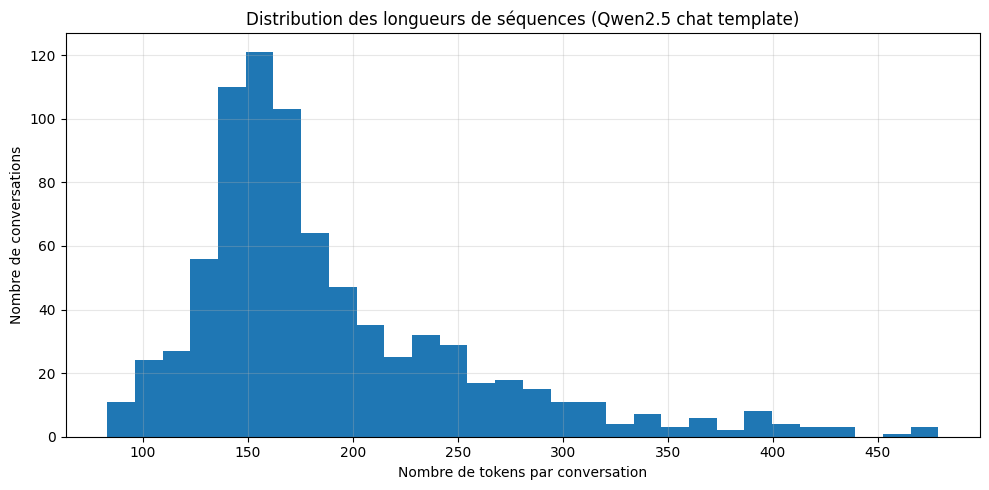

Histogramme enregistré : /content/phase4_outputs/token_length_histogram.png


In [13]:
# ============================================================
# Étape 7 — Statistiques et histogramme
# ============================================================
import numpy as np
import matplotlib
matplotlib.use("Agg") if not IN_COLAB else None
import matplotlib.pyplot as plt

assert STATUS["tokenized"], "La tokenisation n'est pas terminée : relancez l'étape 6."

def compute_stats(values):
    arr = np.asarray(values, dtype=float)
    return {
        "count": int(arr.size),
        "min": int(arr.min()),
        "max": int(arr.max()),
        "mean": round(float(arr.mean()), 2),
        "median": round(float(np.median(arr)), 2),
        "p90": round(float(np.percentile(arr, 90)), 2),
        "p95": round(float(np.percentile(arr, 95)), 2),
        "p99": round(float(np.percentile(arr, 99)), 2),
    }

all_lengths = [n for lens in lengths_by_file.values() for n in lens]
stats_global = compute_stats(all_lengths)
stats_by_file = {fn: compute_stats(lens) for fn, lens in lengths_by_file.items()}

print("===== STATISTIQUES GLOBALES (tokens par conversation) =====")
for key, value in stats_global.items():
    print(f"{key:<8}: {value}")

print("\n===== PAR FICHIER =====")
display(pd.DataFrame(stats_by_file).T)

# ---------- Dépassements de seuils ----------
thresholds_exceeded = {}
print("\n===== SÉQUENCES DÉPASSANT UN SEUIL =====")
for limit in THRESHOLDS:
    count = int(sum(n > limit for n in all_lengths))
    pct = round(count / len(all_lengths) * 100, 2)
    thresholds_exceeded[str(limit)] = {"count": count, "percent": pct}
    print(f"> {limit:<5} tokens : {count:>4}/{len(all_lengths)}  ({pct:.2f} %)")

# ---------- Histogramme (couleurs par défaut de Matplotlib) ----------
HISTOGRAM_PATH = OUTPUT_DIR / "token_length_histogram.png"

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(all_lengths, bins=30)
ax.set_xlabel("Nombre de tokens par conversation")
ax.set_ylabel("Nombre de conversations")
ax.set_title("Distribution des longueurs de séquences (Qwen2.5 chat template)")
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(HISTOGRAM_PATH, dpi=150)
plt.show()
print("Histogramme enregistré :", HISTOGRAM_PATH)

## Étape 8 — Rapports
Trois fichiers sont créés dans `/content/phase4_outputs`. **Aucun contenu textuel de conversation** n'y figure : uniquement des longueurs et des statistiques.

In [14]:
# ============================================================
# Étape 8 — Génération des rapports
# ============================================================
REPORT_JSON = OUTPUT_DIR / "tokenization_report.json"
REPORT_CSV = OUTPUT_DIR / "token_lengths.csv"

report = {
    "phase": "Phase 4 - Verification de la tokenisation Qwen",
    "model": MODEL_ID,
    "tokenizer": {
        "class": type(tokenizer).__name__,
        "vocab_size_base": int(tokenizer.vocab_size),
        "vocab_size_with_special_tokens": int(len(tokenizer)),
        "eos_token": tokenizer.eos_token,
        "eos_token_id": tokenizer.eos_token_id,
        "pad_token": tokenizer.pad_token,
        "pad_token_id": tokenizer.pad_token_id,
        "chat_template_present": tokenizer.chat_template is not None,
        "transformers_version": transformers.__version__,
    },
    "chat_template_options": {"tokenize": True, "add_generation_prompt": False},
    "truncation_applied": False,
    "num_examples": int(len(all_lengths)),
    "dataset": {
        "files": {
            fn: {"expected": EXPECTED_FILES[fn], "found": validation_report[fn]["valid_records"]}
            for fn in EXPECTED_FILES
        },
        "validation_status": "OK",
        "duplicate_warnings": len(warnings_list),
        "cross_file_duplicates": len(duplicate_cross),
    },
    "statistics": {"global": stats_global, "by_file": stats_by_file},
    "thresholds_exceeded": thresholds_exceeded,
    "privacy_note": "Ce rapport ne contient aucun texte de conversation.",
    "generated_at": datetime.now(timezone.utc).isoformat(),
}

with REPORT_JSON.open("w", encoding="utf-8") as handle:
    json.dump(report, handle, indent=2, ensure_ascii=False)

with REPORT_CSV.open("w", newline="", encoding="utf-8") as handle:
    writer = csv.writer(handle)
    writer.writerow(["file", "example_index", "token_count"])
    for filename, lengths in lengths_by_file.items():
        for index, length in enumerate(lengths, 1):
            writer.writerow([filename, index, length])

# ---------- Vérification des fichiers ----------
with REPORT_CSV.open(encoding="utf-8") as handle:
    csv_rows = sum(1 for _ in handle) - 1
assert csv_rows == EXPECTED_TOTAL, f"CSV : {csv_rows} lignes au lieu de {EXPECTED_TOTAL}"

for path in (REPORT_JSON, REPORT_CSV, HISTOGRAM_PATH):
    assert path.exists() and path.stat().st_size > 0, f"Fichier manquant ou vide : {path}"
    print(f"✅ {path.name:<28}{path.stat().st_size / 1024:>8.1f} Ko")

STATUS["reports_written"] = True

✅ tokenization_report.json         2.5 Ko
✅ token_lengths.csv               20.5 Ko
✅ token_length_histogram.png      42.6 Ko


## Étape 9 — Téléchargement
Mettez `DOWNLOAD_REPORTS = False` si vous ne voulez pas lancer les téléchargements. Si votre navigateur bloque les téléchargements multiples, autorisez-les puis relancez la cellule.

In [15]:
# ============================================================
# Étape 9 — Téléchargement des rapports
# ============================================================
DOWNLOAD_REPORTS = True

assert STATUS["reports_written"], "Les rapports ne sont pas générés : relancez l'étape 8."

if DOWNLOAD_REPORTS and IN_COLAB:
    for path in (REPORT_JSON, REPORT_CSV, HISTOGRAM_PATH):
        files.download(str(path))
        time.sleep(1)
    print("Téléchargements lancés.")
else:
    print("Téléchargement ignoré. Fichiers disponibles dans :", OUTPUT_DIR)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Téléchargements lancés.


## Étape 10 — Conclusion
Résumé de la Phase 4. **Le fine-tuning QLoRA n'est pas démarré ici** : il sera traité dans un notebook séparé, après décision sur la longueur maximale de séquence.

In [16]:
# ============================================================
# Étape 10 — Conclusion
# ============================================================
def flag(ok):
    return "✅ oui" if ok else "❌ non"

phase_ok = all(v for k, v in STATUS.items() if k != "repo_cloned")   # le clonage GitHub n est pas bloquant

print("=" * 60)
print("RÉSUMÉ — PHASE 4 : TOKENISATION QWEN")
print("=" * 60)
print("Dataset validé                    :", flag(STATUS["dataset_valid"]))
print("Tokenizer chargé                  :", flag(STATUS["tokenizer_loaded"]))
print("Séquences tokenisées              :", len(all_lengths) if STATUS["tokenized"] else 0)
print("Longueur maximale (tokens)        :", stats_global["max"])
print("Longueur P95 / P99 (tokens)       :", stats_global["p95"], "/", stats_global["p99"])
print("Séquences > 2048 tokens           :",
      f"{thresholds_exceeded['2048']['count']} ({thresholds_exceeded['2048']['percent']} %)")
print("Rapports générés                  :", flag(STATUS["reports_written"]))
print("-" * 60)
print("STATUT DE LA PHASE                :", "✅ TERMINÉE" if phase_ok else "⚠️ INCOMPLÈTE")
print("=" * 60)
print("\nProchaine étape : envoyer tokenization_report.json afin de décider")
print("de max_seq_length avant le premier entraînement QLoRA sur Colab T4.")

RÉSUMÉ — PHASE 4 : TOKENISATION QWEN
Dataset validé                    : ✅ oui
Tokenizer chargé                  : ✅ oui
Séquences tokenisées              : 800
Longueur maximale (tokens)        : 479
Longueur P95 / P99 (tokens)       : 333.05 / 422.04
Séquences > 2048 tokens           : 0 (0.0 %)
Rapports générés                  : ✅ oui
------------------------------------------------------------
STATUT DE LA PHASE                : ✅ TERMINÉE

Prochaine étape : envoyer tokenization_report.json afin de décider
de max_seq_length avant le premier entraînement QLoRA sur Colab T4.
